# Home Credit — final evaluation




## 1. Imports
Use the training environment with pandas, numpy, sklearn, matplotlib, seaborn, joblib, XGBoost, LightGBM, CatBoost and Optuna installed.

In [2]:
from pathlib import Path
import json
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    precision_recall_curve, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)
from sklearn.calibration import calibration_curve

SEED = 42
sns.set_theme(style="whitegrid")

## 2. Paths and evaluation settings


In [3]:
PROJECT_ROOT = Path(r"C:\Case Study Trees\HomeCreditStudy")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
TRAINING_RESULTS = PROJECT_ROOT / "results"
EVAL_DIR = TRAINING_RESULTS / "home_credit_evaluation"
FIGURE_DIR = EVAL_DIR / "figures"
PREDICTION_DIR = EVAL_DIR / "predictions"

for folder in [EVAL_DIR, FIGURE_DIR, PREDICTION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

TIMING_BATCH_SIZE = 10000
TIMING_REPEATS = 5
N_BOOTSTRAPS = 200

reference_valid_ids = pd.read_csv(PROCESSED_DIR / "engineered" / "valid_ids.csv")["SK_ID_CURR"]
reference_test_ids = pd.read_csv(PROCESSED_DIR / "engineered" / "test_ids.csv")["SK_ID_CURR"]
assert reference_valid_ids.is_unique and reference_test_ids.is_unique
assert set(reference_valid_ids).isdisjoint(reference_test_ids)
print("Validation applicants:", len(reference_valid_ids))
print("Test applicants:", len(reference_test_ids))
print("Figures:", FIGURE_DIR)

Validation applicants: 46127
Test applicants: 46127
Figures: C:\Case Study Trees\HomeCreditStudy\results\home_credit_evaluation\figures


## 3. Inventory the saved models before evaluation


In [4]:
feature_folders = {
    "Engineered": "engineered",
    "Engineered + filtered": "engineered_filtered"
}
algorithm_names = {"rf": "Random Forest", "xgb": "XGBoost", "lgb": "LightGBM", "cat": "CatBoost"}
model_records = []

for representation, keys in [("One-hot", ["rf", "xgb", "lgb", "cat"]),
                              ("Native", ["xgb", "lgb", "cat"])]:
    artifact_folder = ARTIFACT_DIR if representation == "One-hot" else ARTIFACT_DIR / "native"
    result_folder = TRAINING_RESULTS if representation == "One-hot" else TRAINING_RESULTS / "native"

    for key in keys:
        tuned_table = pd.read_csv(result_folder / f"{key}_tuned_validation.csv")
        assert len(tuned_table) == 1
        feature_label = tuned_table.iloc[0]["Feature_Set"]
        feature_folder = feature_folders[feature_label]

        if representation == "Native":
            selection = pd.read_csv(result_folder / f"{key}_selected_configuration.csv").iloc[0]
            assert selection["Feature_Folder"] == feature_folder
            baseline_filename = selection["Baseline_Model_File"]
            tuned_filename = selection["Tuned_Model_File"]
            input_info_path = artifact_folder / selection["Input_Info_File"]
        else:
            suffix = "filtered" if feature_folder == "engineered_filtered" else "engineered"
            baseline_filename = f"{key}_{suffix}_baseline.joblib"
            candidates = [artifact_folder / f"{key}_{feature_folder}_tuned.joblib",
                          artifact_folder / f"{key}_{suffix}_tuned.joblib"]
            existing = list(dict.fromkeys(p for p in candidates if p.exists()))
            if len(existing) != 1:
                raise ValueError(f"Expected exactly one tuned file for {key}: {existing}")
            tuned_filename = existing[0].name
            input_info_path = None

        for stage, filename in [("Baseline", baseline_filename), ("Tuned", tuned_filename)]:
            path = artifact_folder / filename
            if not path.exists():
                raise FileNotFoundError(path)
            if representation == "Native" and not input_info_path.exists():
                raise FileNotFoundError(input_info_path)

            baseline_comparison = pd.read_csv(result_folder / f"{key}_baseline_comparison.csv")
            baseline_row = baseline_comparison.loc[
                baseline_comparison["Feature_Set"] == feature_label
            ].iloc[0]
            training_row = baseline_row if stage == "Baseline" else tuned_table.iloc[0]
            model_id = f"{key}_{representation.lower().replace('-', '')}_{stage.lower()}"

            model_records.append({
                "Model_ID": model_id, "Algorithm_Key": key,
                "Algorithm": algorithm_names[key], "Representation": representation,
                "Version": stage, "Feature_Set": feature_label,
                "Feature_Folder": feature_folder, "Model_Path": str(path),
                "Input_Info_Path": str(input_info_path) if input_info_path else "",
                "Validation_AUC_Recorded": float(training_row["ROC_AUC"]),
                "Fit_Seconds": float(training_row["Fit_Seconds"]),
                "Tuning_Seconds": float(training_row.get("Tuning_Seconds", np.nan)) if stage == "Tuned" else 0.0
            })

registry = pd.DataFrame(model_records)
assert len(registry) == 14
registry.to_csv(EVAL_DIR / "model_registry.csv", index=False)
display(registry[["Model_ID", "Algorithm", "Representation", "Version", "Feature_Set", "Model_Path"]])
print("All 14 model files located.")

,Model_ID,Algorithm,Representation,Version,Feature_Set,Model_Path
0,rf_onehot_baseline,Random Forest,One-hot,Baseline,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
1,rf_onehot_tuned,Random Forest,One-hot,Tuned,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
2,xgb_onehot_baseline,XGBoost,One-hot,Baseline,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
3,xgb_onehot_tuned,XGBoost,One-hot,Tuned,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
4,lgb_onehot_baseline,LightGBM,One-hot,Baseline,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
5,lgb_onehot_tuned,LightGBM,One-hot,Tuned,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
6,cat_onehot_baseline,CatBoost,One-hot,Baseline,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
7,cat_onehot_tuned,CatBoost,One-hot,Tuned,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
8,xgb_native_baseline,XGBoost,Native,Baseline,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...
9,xgb_native_tuned,XGBoost,Native,Tuned,Engineered + filtered,C:\Case Study Trees\HomeCreditStudy\artifacts\...


All 14 model files located.


## 4. Load matching features and restore their types


In [5]:
def load_model_inputs(record, split):
    base = PROCESSED_DIR / "native" if record["Representation"] == "Native" else PROCESSED_DIR
    folder = base / record["Feature_Folder"]
    target = pd.read_csv(folder / f"y_{split}.csv")["TARGET"]
    ids = pd.read_csv(folder / f"{split}_ids.csv")["SK_ID_CURR"]
    expected_ids = reference_valid_ids if split == "valid" else reference_test_ids
    pd.testing.assert_series_equal(ids, expected_ids)
    expected_target = pd.read_csv(PROCESSED_DIR / "engineered" / f"y_{split}.csv")["TARGET"]
    pd.testing.assert_series_equal(target, expected_target)
    assert target.isin([0, 1]).all()

    if record["Representation"] == "Native":
        info = joblib.load(record["Input_Info_Path"])
        categorical_columns = info["categorical_columns"]
        dtypes = {c: str for c in categorical_columns}
        dtypes.update({c: "float32" for c in info["original_columns"] if c not in categorical_columns})
        data = pd.read_csv(folder / f"X_{split}.csv", dtype=dtypes, keep_default_na=False)
        assert data.columns.tolist() == info["original_columns"]
        original_names = info["original_columns"]
        for column in categorical_columns:
            levels = info["category_levels"][column]
            data[column] = data[column].replace("", "Missing")
            data[column] = data[column].where(data[column].isin(levels), "Missing")
            if record["Algorithm_Key"] in ["xgb", "lgb"]:
                data[column] = pd.Categorical(data[column], categories=levels)
        data.columns = info["model_columns"]
    else:
        data = pd.read_csv(folder / f"X_{split}.csv", dtype="float32")
        original_names = data.columns.tolist()
        if record["Algorithm_Key"] == "lgb":
            suffix = "filtered" if record["Feature_Folder"] == "engineered_filtered" else "engineered"
            mapping = pd.read_csv(ARTIFACT_DIR / f"lgb_{suffix}_feature_mapping.csv")
            assert data.columns.tolist() == mapping["Original_Name"].tolist()
            data.columns = mapping["LightGBM_Name"].tolist()

    assert len(data) == len(target)
    numeric = data.select_dtypes(include="number")
    assert np.isfinite(numeric.to_numpy()).all()
    return data, target, ids, original_names

## 5. Validation thresholds and fixed-batch timing — before test scoring


In [ ]:
from catboost import CatBoostClassifier

validation_predictions = {}
validation_records = []

for _, record in registry.iterrows():
    print("Validation:", record["Model_ID"], flush=True)

    model = joblib.load(record["Model_Path"])
    data, target, ids, original_names = load_model_inputs(record, "valid")


    if isinstance(model, CatBoostClassifier):
        expected_features = len(model.feature_names_)
        assert model.tree_count_ > 0, "CatBoost has no trained trees."
    else:
        expected_features = model.n_features_in_

    assert expected_features == data.shape[1], (
        f"{record['Model_ID']}: expected {expected_features} "
        f"features, loaded {data.shape[1]}"
    )

    probability = model.predict_proba(data)[:, 1]

    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()

    validation_predictions[record["Model_ID"]] = probability


    precision, recall, thresholds = precision_recall_curve(
        target, probability
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    )

    threshold = float(thresholds[np.argmax(f1)])
    validation_auc = roc_auc_score(target, probability)


    if not np.isclose(
        validation_auc,
        record["Validation_AUC_Recorded"],
        atol=1e-5,
        rtol=0
    ):
        raise ValueError(
            f"{record['Model_ID']}: validation AUC is "
            f"{validation_auc:.6f}, but the saved result is "
            f"{record['Validation_AUC_Recorded']:.6f}. "
            "Check the model and input files."
        )

    batch = data.iloc[:min(TIMING_BATCH_SIZE, len(data))]
    model.predict_proba(batch)

    times = []

    for repeat in range(TIMING_REPEATS):
        start = time.perf_counter()
        model.predict_proba(batch)
        times.append(time.perf_counter() - start)

    validation_records.append({
        "Model_ID": record["Model_ID"],
        "Threshold": threshold,
        "Validation_ROC_AUC": validation_auc,
        "Validation_AP": average_precision_score(target, probability),
        "Validation_F1": float(np.max(f1)),
        "Timing_Batch_Rows": len(batch),
        "Prediction_Seconds_Per_10000": (
            np.median(times) * 10000 / len(batch)
        ),
        "Prediction_Seconds_P25_Per_10000": (
            np.percentile(times, 25) * 10000 / len(batch)
        ),
        "Prediction_Seconds_P75_Per_10000": (
            np.percentile(times, 75) * 10000 / len(batch)
        )
    })

    pd.DataFrame({
        "SK_ID_CURR": ids,
        "TARGET": target,
        "Probability": probability
    }).to_csv(
        PREDICTION_DIR / f"{record['Model_ID']}_validation.csv",
        index=False
    )

    del model, data
    gc.collect()

validation_results = pd.DataFrame(validation_records)

evaluation_columns = [
    column for column in validation_results.columns
    if column != "Model_ID"
]

registry = registry.drop(
    columns=evaluation_columns,
    errors="ignore"
)

registry = registry.merge(
    validation_results,
    on="Model_ID",
    validate="one_to_one"
)

registry.to_csv(
    EVAL_DIR / "frozen_evaluation_manifest.csv",
    index=False
)

champions = {}

for representation in ["One-hot", "Native"]:
    candidates = registry[
        (registry["Representation"] == representation)
        & (registry["Version"] == "Tuned")
    ]

    best_index = candidates["Validation_ROC_AUC"].idxmax()
    champions[representation] = candidates.loc[best_index, "Model_ID"]

(EVAL_DIR / "validation_selected_representatives.json").write_text(
    json.dumps(champions, indent=2),
    encoding="utf-8"
)

display(
    registry[[
        "Model_ID",
        "Threshold",
        "Validation_ROC_AUC",
        "Validation_F1",
        "Prediction_Seconds_Per_10000"
    ]]
)

print("Plot representatives selected by validation:", champions)

Validation: rf_onehot_baseline
Validation: rf_onehot_tuned
Validation: xgb_onehot_baseline
Validation: xgb_onehot_tuned
Validation: lgb_onehot_baseline
Validation: lgb_onehot_tuned
Validation: cat_onehot_baseline
Validation: cat_onehot_tuned
Validation: xgb_native_baseline
Validation: xgb_native_tuned
Validation: lgb_native_baseline
Validation: lgb_native_tuned
Validation: cat_native_baseline
Validation: cat_native_tuned


,Model_ID,Threshold,Validation_ROC_AUC,Validation_F1,Prediction_Seconds_Per_10000
0,rf_onehot_baseline,0.133609,0.746359,0.300569,0.106499
1,rf_onehot_tuned,0.136815,0.751456,0.300800,0.288260
2,xgb_onehot_baseline,0.156682,0.761575,0.306886,0.037557
3,xgb_onehot_tuned,0.136327,0.764576,0.307020,0.055884
4,lgb_onehot_baseline,0.149990,0.761417,0.306213,0.103856
5,lgb_onehot_tuned,0.140699,0.765178,0.308187,0.425932
6,cat_onehot_baseline,0.156011,0.762764,0.308555,0.012075
7,cat_onehot_tuned,0.146734,0.765761,0.314030,0.013951
8,xgb_native_baseline,0.156162,0.759839,0.303650,0.083870
9,xgb_native_tuned,0.147363,0.765023,0.308752,0.119483


Plot representatives selected by validation: {'One-hot': 'cat_onehot_tuned', 'Native': 'xgb_native_tuned'}


## 6. Test predictions and master results


In [11]:
test_predictions = {}
test_records = []
y_test = None

for _, record in registry.iterrows():
    print("Test:", record["Model_ID"], flush=True)
    model = joblib.load(record["Model_Path"])
    data, target, ids, original_names = load_model_inputs(record, "test")
    y_test = target.to_numpy()
    probability = model.predict_proba(data)[:, 1]
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    predicted = (probability >= record["Threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()

    order = np.argsort(-probability, kind="stable")
    k = max(1, int(np.ceil(0.10 * len(y_test))))
    positives_in_top = y_test[order[:k]].sum()
    top_precision = positives_in_top / k
    top_recall = positives_in_top / y_test.sum()

    result = record.to_dict()
    result.update({
        "Dataset": "Home Credit", "Test_Rows": len(target),
        "Positive_Prevalence": target.mean(), "ROC_AUC": roc_auc_score(y_test, probability),
        "Average_Precision": average_precision_score(y_test, probability),
        "Log_Loss": log_loss(y_test, probability, labels=[0, 1]),
        "Brier_Score": np.mean((probability - y_test) ** 2),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "Accuracy": accuracy_score(y_test, predicted),
        "Flagged_Percentage": predicted.mean() * 100,
        "Recall_At_Top_10_Percent": top_recall,
        "Precision_At_Top_10_Percent": top_precision,
        "Lift_At_Top_10_Percent": top_precision / target.mean(),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Model_Size_MB": Path(record["Model_Path"]).stat().st_size / (1024 ** 2)
    })
    test_records.append(result)
    test_predictions[record["Model_ID"]] = probability
    pd.DataFrame({
        "SK_ID_CURR": ids, "TARGET": target, "Probability": probability,
        "Threshold": record["Threshold"], "Prediction": predicted
    }).to_csv(PREDICTION_DIR / f"{record['Model_ID']}_test.csv", index=False)
    del model, data
    gc.collect()

results = pd.DataFrame(test_records)
results.to_csv(EVAL_DIR / "home_credit_test_results.csv", index=False)
display(results[["Algorithm", "Representation", "Version", "Feature_Set", "ROC_AUC",
                 "Average_Precision", "Log_Loss", "Brier_Score", "Recall", "Precision",
                 "Recall_At_Top_10_Percent"]].sort_values("ROC_AUC", ascending=False).round(4))
print("Test prevalence:", round(float(np.mean(y_test)), 4))
print("All-negative accuracy:", round(float(1 - np.mean(y_test)), 4))

Test: rf_onehot_baseline
Test: rf_onehot_tuned
Test: xgb_onehot_baseline
Test: xgb_onehot_tuned
Test: lgb_onehot_baseline
Test: lgb_onehot_tuned
Test: cat_onehot_baseline
Test: cat_onehot_tuned
Test: xgb_native_baseline
Test: xgb_native_tuned
Test: lgb_native_baseline
Test: lgb_native_tuned
Test: cat_native_baseline
Test: cat_native_tuned


,Algorithm,Representation,Version,Feature_Set,ROC_AUC,Average_Precision,Log_Loss,Brier_Score,Recall,Precision,Recall_At_Top_10_Percent
3,XGBoost,One-hot,Tuned,Engineered + filtered,0.7636,0.2533,0.2442,0.0674,0.4670,0.2346,0.3483
7,CatBoost,One-hot,Tuned,Engineered + filtered,0.7635,0.2554,0.2443,0.0673,0.4382,0.2492,0.3488
5,LightGBM,One-hot,Tuned,Engineered + filtered,0.7635,0.2525,0.2443,0.0674,0.4484,0.2369,0.3464
9,XGBoost,Native,Tuned,Engineered + filtered,0.7633,0.2535,0.2443,0.0674,0.4339,0.2468,0.3485
13,CatBoost,Native,Tuned,Engineered,0.7632,0.2546,0.2444,0.0673,0.4227,0.2521,0.3459
11,LightGBM,Native,Tuned,Engineered,0.7624,0.2498,0.2448,0.0675,0.4452,0.2411,0.3445
4,LightGBM,One-hot,Baseline,Engineered + filtered,0.7618,0.2527,0.2447,0.0674,0.4326,0.2519,0.3445
2,XGBoost,One-hot,Baseline,Engineered + filtered,0.7614,0.2496,0.2449,0.0675,0.4068,0.2548,0.3443
12,CatBoost,Native,Baseline,Engineered,0.7613,0.2512,0.2451,0.0675,0.4133,0.2506,0.3413
10,LightGBM,Native,Baseline,Engineered,0.7609,0.2493,0.2452,0.0676,0.4466,0.2386,0.3426


Test prevalence: 0.0807
All-negative accuracy: 0.9193


## 7. Paired bootstrap uncertainty


In [12]:
rng = np.random.default_rng(SEED)
positive_positions = np.flatnonzero(y_test == 1)
negative_positions = np.flatnonzero(y_test == 0)
bootstrap_auc = {model_id: [] for model_id in test_predictions}
bootstrap_ap = {model_id: [] for model_id in test_predictions}

for repeat in range(N_BOOTSTRAPS):
    positions = np.concatenate([
        rng.choice(positive_positions, len(positive_positions), replace=True),
        rng.choice(negative_positions, len(negative_positions), replace=True)
    ])
    sampled_y = y_test[positions]
    for model_id, probability in test_predictions.items():
        bootstrap_auc[model_id].append(roc_auc_score(sampled_y, probability[positions]))
        bootstrap_ap[model_id].append(average_precision_score(sampled_y, probability[positions]))

interval_rows = []
for model_id in test_predictions:
    interval_rows.append({
        "Model_ID": model_id,
        "AUC_Lower": np.percentile(bootstrap_auc[model_id], 2.5),
        "AUC_Upper": np.percentile(bootstrap_auc[model_id], 97.5),
        "AP_Lower": np.percentile(bootstrap_ap[model_id], 2.5),
        "AP_Upper": np.percentile(bootstrap_ap[model_id], 97.5)
    })
results = results.merge(pd.DataFrame(interval_rows), on="Model_ID", validate="one_to_one")
results.to_csv(EVAL_DIR / "home_credit_test_results_with_intervals.csv", index=False)
display(results[["Model_ID", "ROC_AUC", "AUC_Lower", "AUC_Upper", "Average_Precision", "AP_Lower", "AP_Upper"]].round(4))

,Model_ID,ROC_AUC,AUC_Lower,AUC_Upper,Average_Precision,AP_Lower,AP_Upper
0,rf_onehot_baseline,0.7451,0.7360,0.7524,0.2330,0.2209,0.2438
1,rf_onehot_tuned,0.7506,0.7415,0.7574,0.2377,0.2250,0.2480
2,xgb_onehot_baseline,0.7614,0.7535,0.7680,0.2496,0.2385,0.2617
3,xgb_onehot_tuned,0.7636,0.7560,0.7705,0.2533,0.2419,0.2649
4,lgb_onehot_baseline,0.7618,0.7537,0.7688,0.2527,0.2418,0.2634
5,lgb_onehot_tuned,0.7635,0.7554,0.7701,0.2525,0.2412,0.2641
6,cat_onehot_baseline,0.7606,0.7526,0.7675,0.2503,0.2381,0.2612
7,cat_onehot_tuned,0.7635,0.7558,0.7708,0.2554,0.2440,0.2659
8,xgb_native_baseline,0.7597,0.7523,0.7664,0.2470,0.2361,0.2588
9,xgb_native_tuned,0.7633,0.7556,0.7697,0.2535,0.2414,0.2654


## 8. Plot labels and saving


In [13]:
results["Label"] = results["Algorithm"] + " | " + results["Representation"] + " | " + results["Version"]
label_lookup = results.set_index("Model_ID")["Label"].to_dict()
colors = {"Random Forest": "#67758d", "XGBoost": "#e76f51", "LightGBM": "#2a9d8f", "CatBoost": "#aa6cc5"}

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

## 9. All-pipeline ROC-AUC with uncertainty


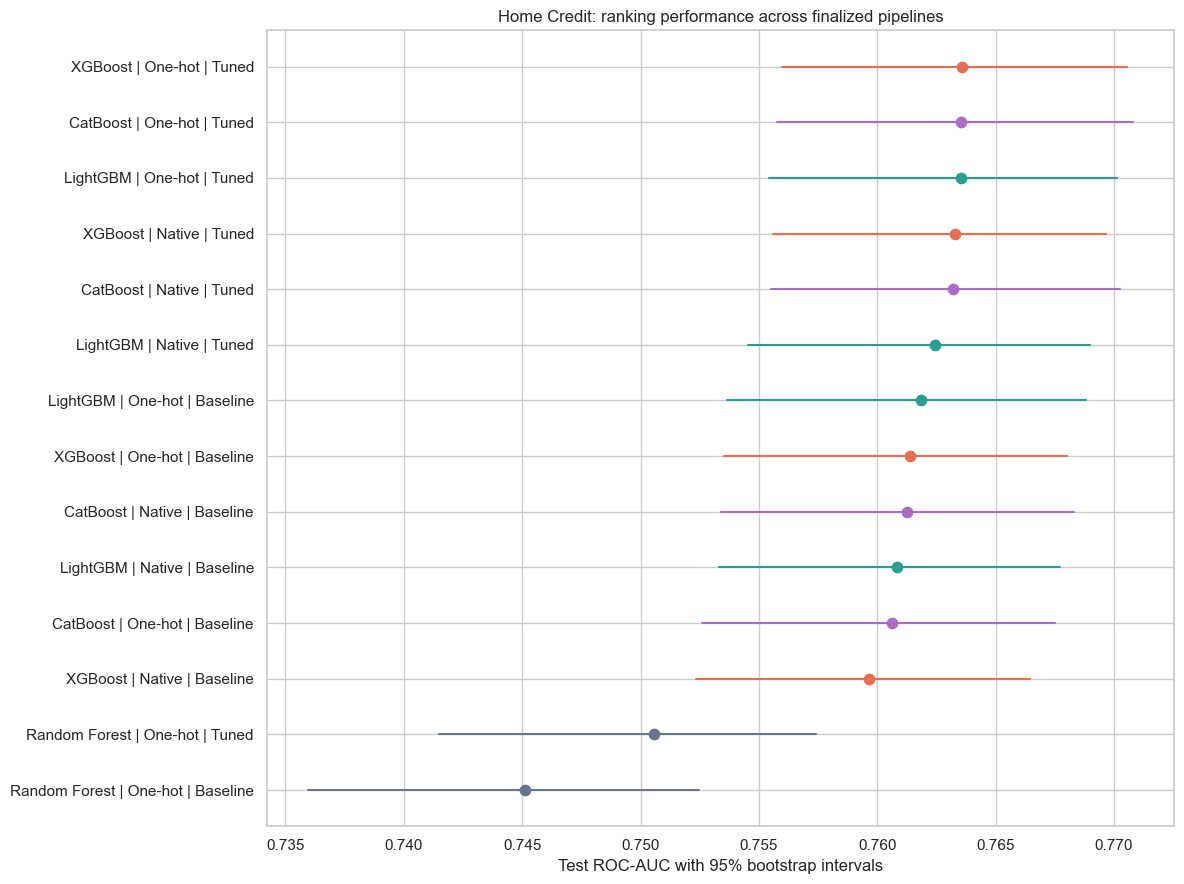

In [14]:
plot_data = results.sort_values("ROC_AUC")
plt.figure(figsize=(12, 9))
for position, (_, row) in enumerate(plot_data.iterrows()):
    plt.plot([row["AUC_Lower"], row["AUC_Upper"]], [position, position], color=colors[row["Algorithm"]])
    plt.scatter(row["ROC_AUC"], position, color=colors[row["Algorithm"]], s=55)
plt.yticks(range(len(plot_data)), plot_data["Label"])
plt.xlabel("Test ROC-AUC with 95% bootstrap intervals")
plt.title("Home Credit: ranking performance across finalized pipelines")
save_figure("01_all_models_auc_intervals")

## 10. ROC and precision–recall curves


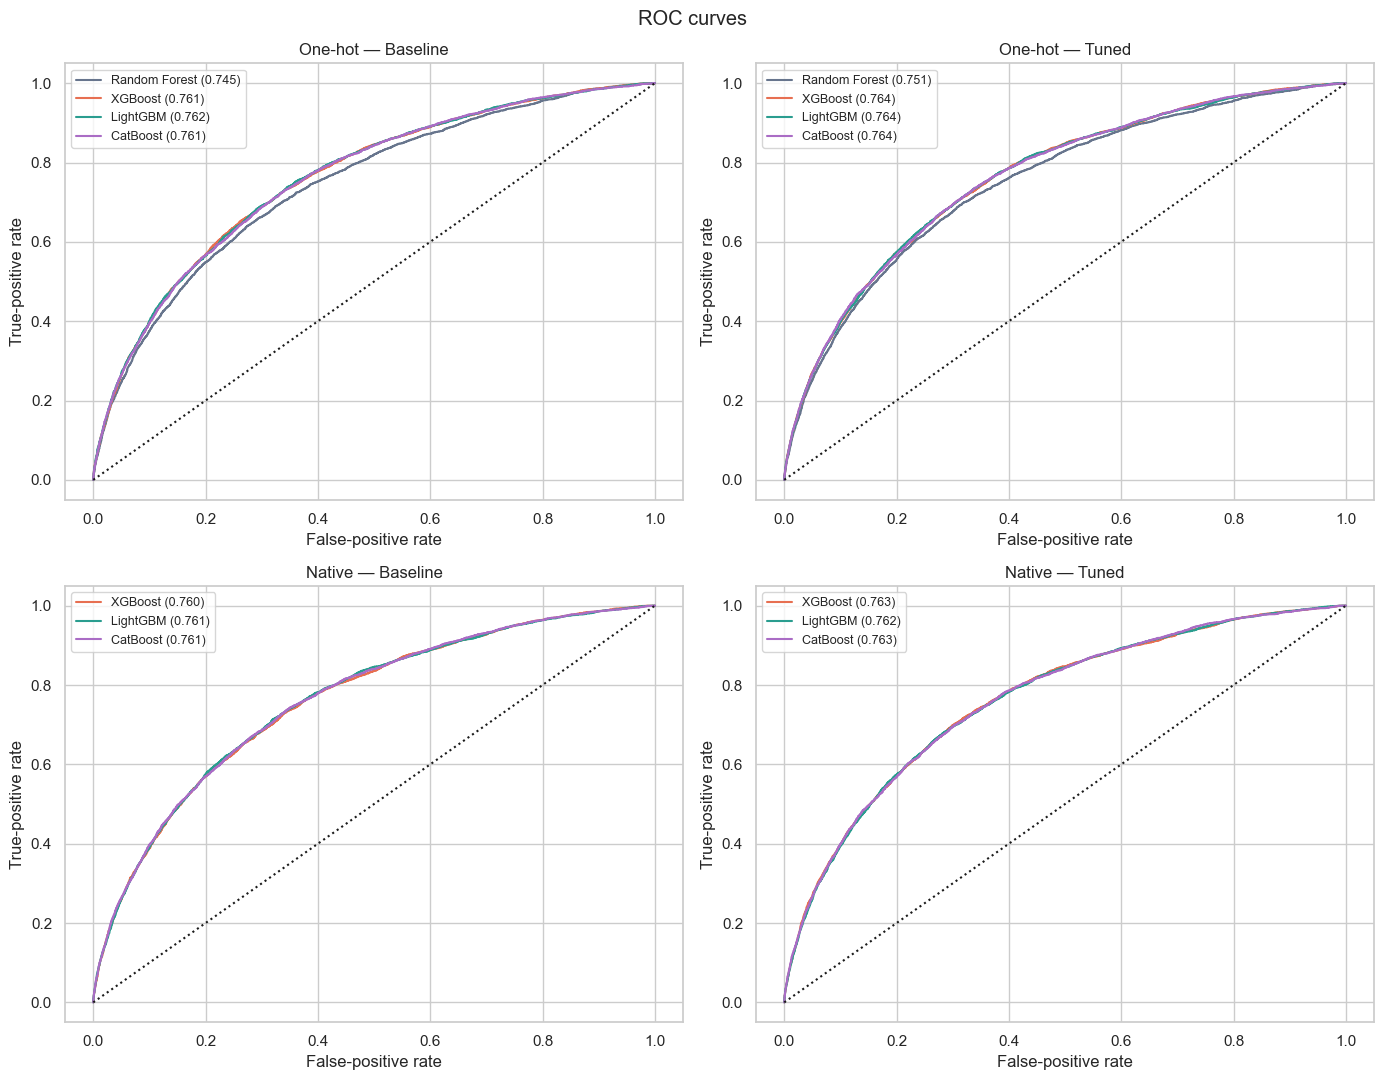

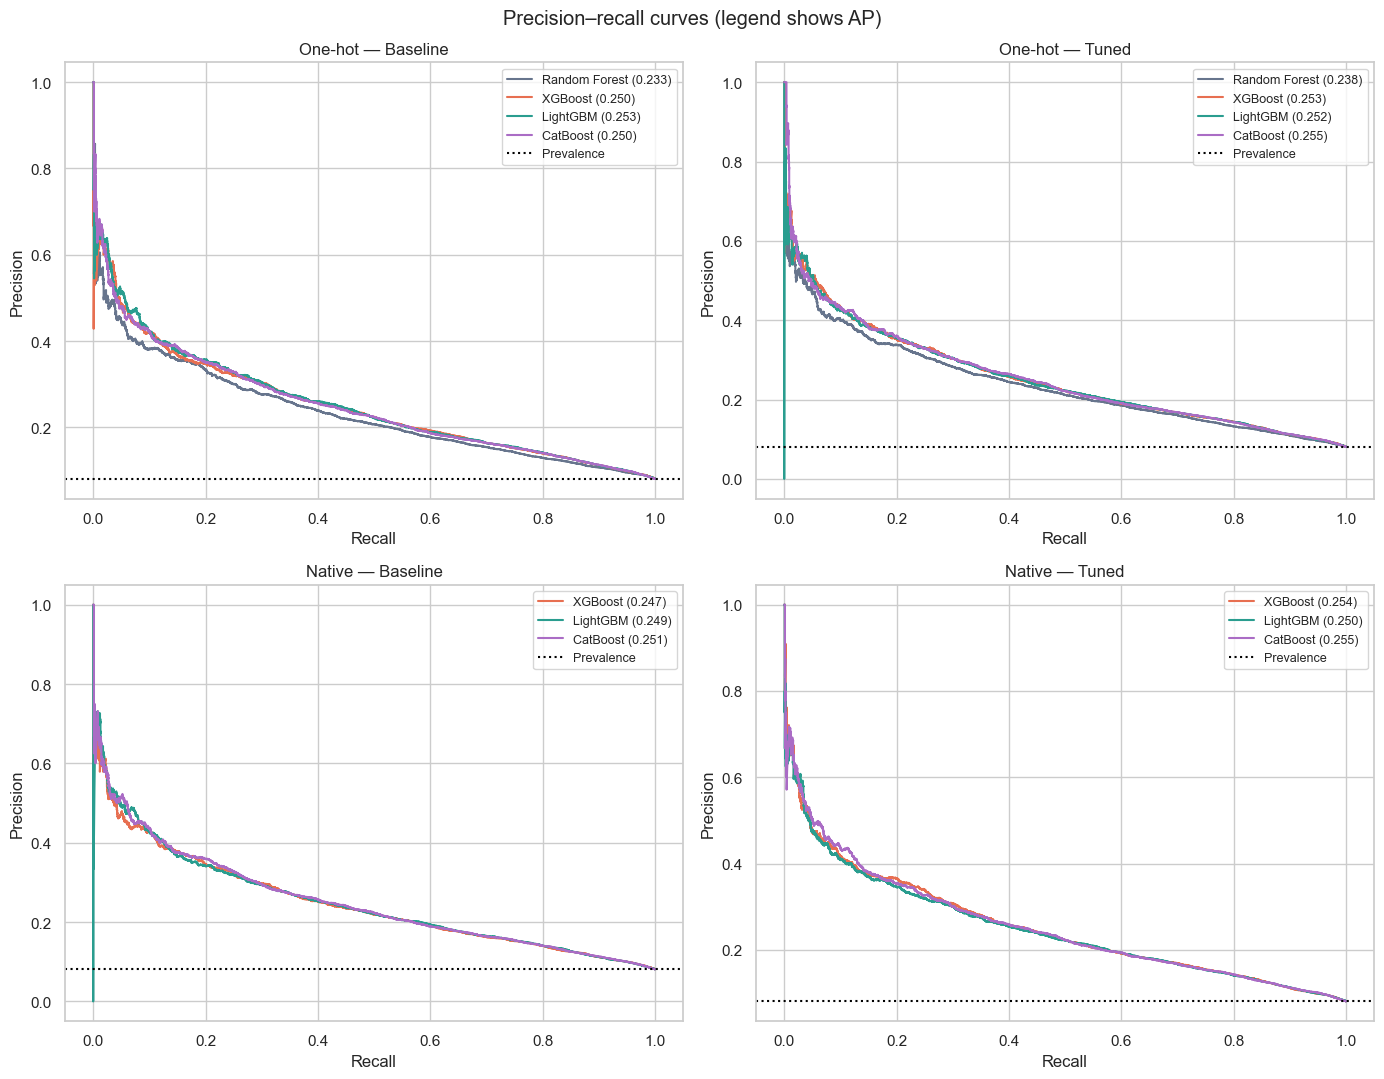

In [15]:
for graph in ["roc", "pr"]:
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    for row_number, representation in enumerate(["One-hot", "Native"]):
        for column_number, stage in enumerate(["Baseline", "Tuned"]):
            ax = axes[row_number, column_number]
            subset = results[(results["Representation"] == representation) & (results["Version"] == stage)]
            for _, record in subset.iterrows():
                probability = test_predictions[record["Model_ID"]]
                if graph == "roc":
                    x, y, _ = roc_curve(y_test, probability)
                    score = record["ROC_AUC"]
                else:
                    precision, recall, _ = precision_recall_curve(y_test, probability)
                    x, y = recall, precision
                    score = record["Average_Precision"]
                ax.plot(x, y, label=f"{record['Algorithm']} ({score:.3f})", color=colors[record["Algorithm"]])
            if graph == "roc":
                ax.plot([0, 1], [0, 1], "k:")
                ax.set(xlabel="False-positive rate", ylabel="True-positive rate")
            else:
                ax.axhline(np.mean(y_test), color="black", linestyle=":", label="Prevalence")
                ax.set(xlabel="Recall", ylabel="Precision")
            ax.set_title(f"{representation} — {stage}")
            ax.legend(fontsize=9)
    fig.suptitle("ROC curves" if graph == "roc" else "Precision–recall curves (legend shows AP)")
    save_figure(f"02_{graph}_curves")

## 11. Did tuning help?


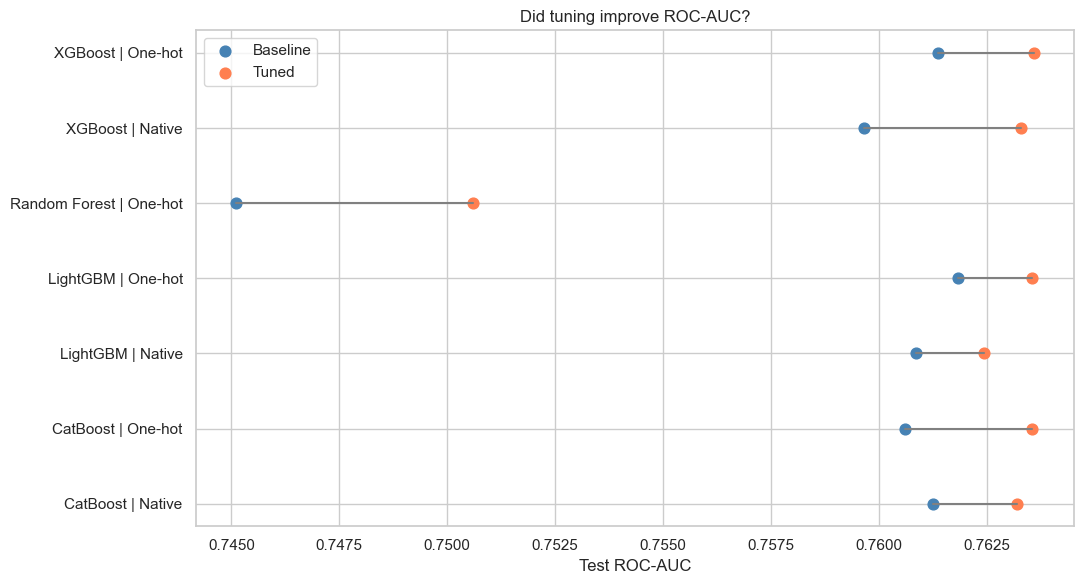

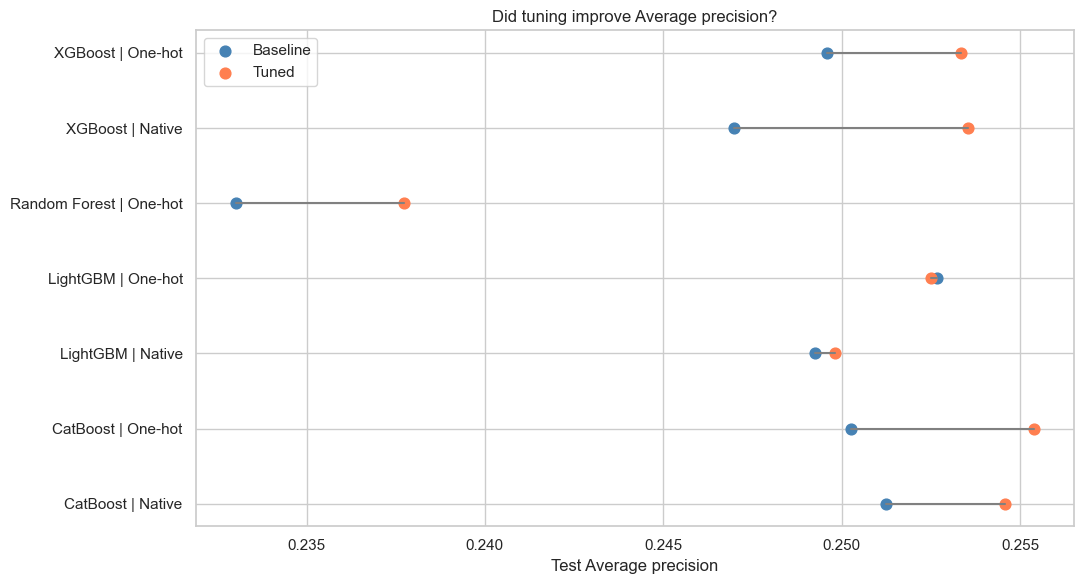

In [16]:
for metric, title in [("ROC_AUC", "ROC-AUC"), ("Average_Precision", "Average precision")]:
    pairs = results.pivot(index=["Algorithm", "Representation"], columns="Version", values=metric).reset_index()
    pairs["Change"] = pairs["Tuned"] - pairs["Baseline"]
    pairs.to_csv(EVAL_DIR / f"tuning_gain_{metric}.csv", index=False)
    plt.figure(figsize=(11, 6))
    for position, row in pairs.iterrows():
        plt.plot([row["Baseline"], row["Tuned"]], [position, position], color="gray")
    plt.scatter(pairs["Baseline"], range(len(pairs)), label="Baseline", color="steelblue", s=60)
    plt.scatter(pairs["Tuned"], range(len(pairs)), label="Tuned", color="coral", s=60)
    plt.yticks(range(len(pairs)), pairs["Algorithm"] + " | " + pairs["Representation"])
    plt.xlabel(f"Test {title}")
    plt.title(f"Did tuning improve {title}?")
    plt.legend()
    save_figure(f"03_tuning_gain_{metric}")

## 12. Native versus one-hot


,Algorithm,Representation,Version,Feature_Set,ROC_AUC
0,Random Forest,One-hot,Baseline,Engineered + filtered,0.7451
1,Random Forest,One-hot,Tuned,Engineered + filtered,0.7506
2,XGBoost,One-hot,Baseline,Engineered + filtered,0.7614
3,XGBoost,One-hot,Tuned,Engineered + filtered,0.7636
4,LightGBM,One-hot,Baseline,Engineered + filtered,0.7618
5,LightGBM,One-hot,Tuned,Engineered + filtered,0.7635
6,CatBoost,One-hot,Baseline,Engineered + filtered,0.7606
7,CatBoost,One-hot,Tuned,Engineered + filtered,0.7635
8,XGBoost,Native,Baseline,Engineered + filtered,0.7597
9,XGBoost,Native,Tuned,Engineered + filtered,0.7633


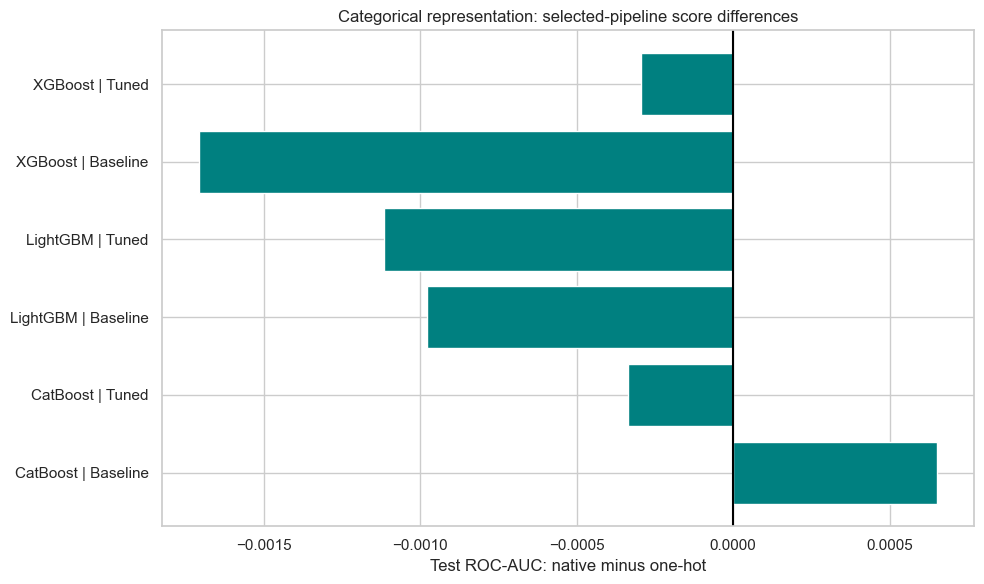

In [17]:
native_pairs = results[results["Algorithm"] != "Random Forest"].pivot(
    index=["Algorithm", "Version"], columns="Representation", values="ROC_AUC"
).reset_index()
native_pairs["Native_Minus_Onehot"] = native_pairs["Native"] - native_pairs["One-hot"]
native_pairs.to_csv(EVAL_DIR / "native_vs_onehot_auc.csv", index=False)
display(results[["Algorithm", "Representation", "Version", "Feature_Set", "ROC_AUC"]].round(4))
plt.figure(figsize=(10, 6))
plt.barh(native_pairs["Algorithm"] + " | " + native_pairs["Version"], native_pairs["Native_Minus_Onehot"], color="teal")
plt.axvline(0, color="black")
plt.xlabel("Test ROC-AUC: native minus one-hot")
plt.title("Categorical representation: selected-pipeline score differences")
save_figure("04_native_vs_onehot")

## 13. Calibration and probability distributions


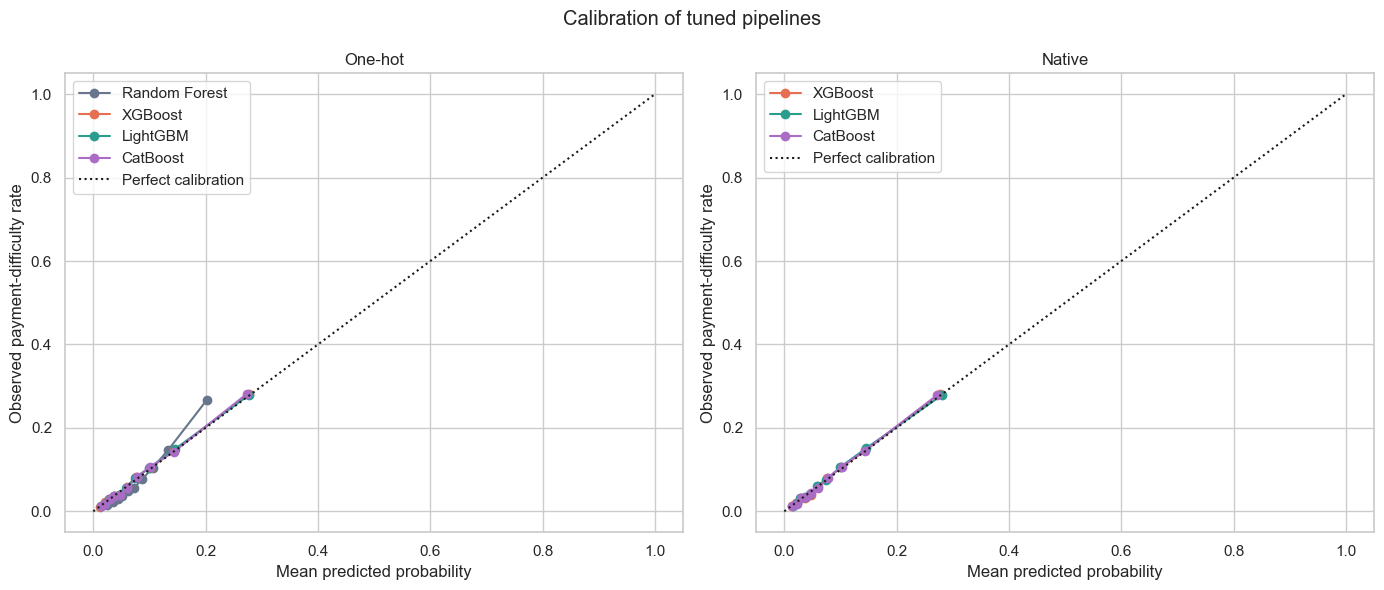

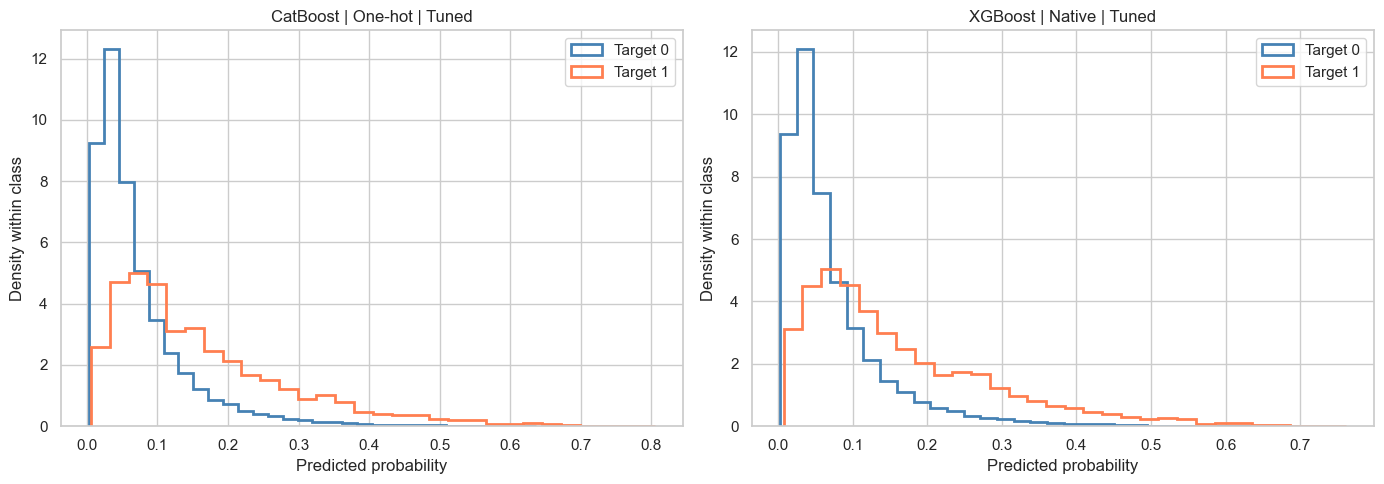

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, representation in zip(axes, ["One-hot", "Native"]):
    subset = results[(results["Representation"] == representation) & (results["Version"] == "Tuned")]
    for _, record in subset.iterrows():
        p = test_predictions[record["Model_ID"]]
        observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
        ax.plot(predicted, observed, marker="o", color=colors[record["Algorithm"]], label=record["Algorithm"])
        frame = pd.DataFrame({"Probability": p, "Target": y_test})
        frame["Bin"] = pd.qcut(frame["Probability"], q=10, duplicates="drop")
        frame.groupby("Bin", observed=True).agg(
            Applicants=("Target", "size"), Predicted=("Probability", "mean"), Observed=("Target", "mean")
        ).to_csv(EVAL_DIR / f"{record['Model_ID']}_calibration_bins.csv")
    ax.plot([0, 1], [0, 1], "k:", label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed payment-difficulty rate", title=representation)
    ax.legend()
fig.suptitle("Calibration of tuned pipelines")
save_figure("05_calibration")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (representation, model_id) in zip(axes, champions.items()):
    p = test_predictions[model_id]
    for target_value, color in [(0, "steelblue"), (1, "coral")]:
        ax.hist(p[y_test == target_value], bins=30, density=True, histtype="step", linewidth=2,
                color=color, label=f"Target {target_value}")
    ax.set(title=label_lookup[model_id], xlabel="Predicted probability", ylabel="Density within class")
    ax.legend()
save_figure("06_probability_distributions")

## 14. Review capacity: cumulative gains and lift


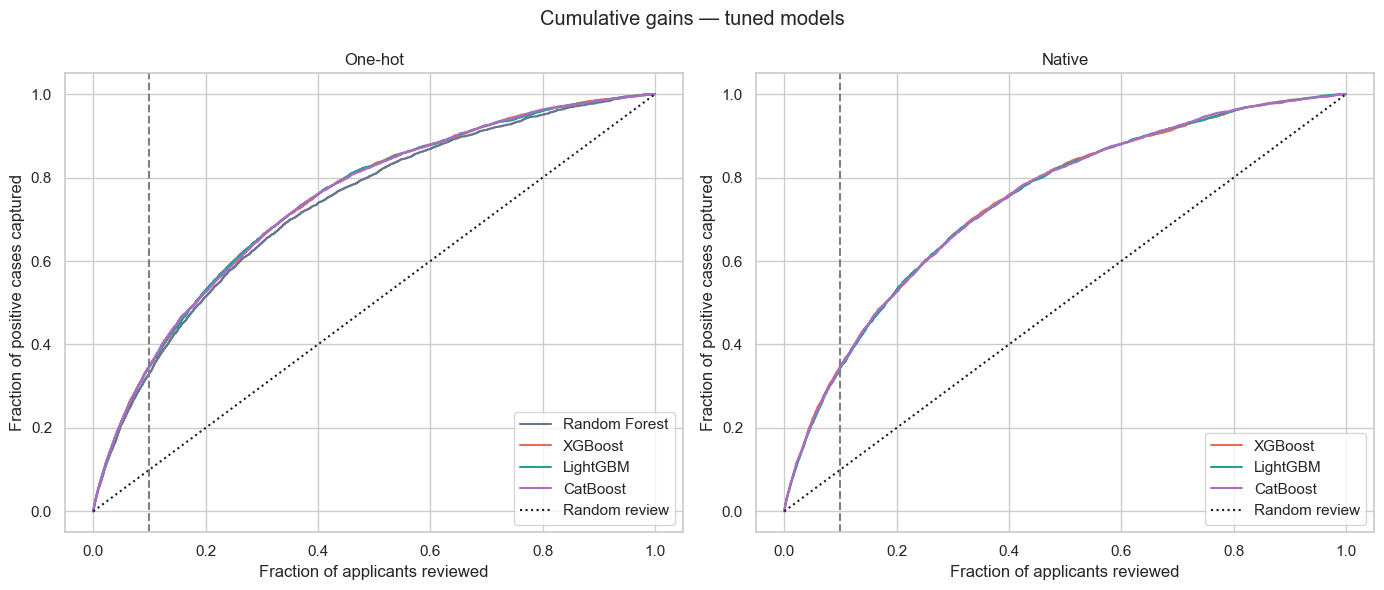

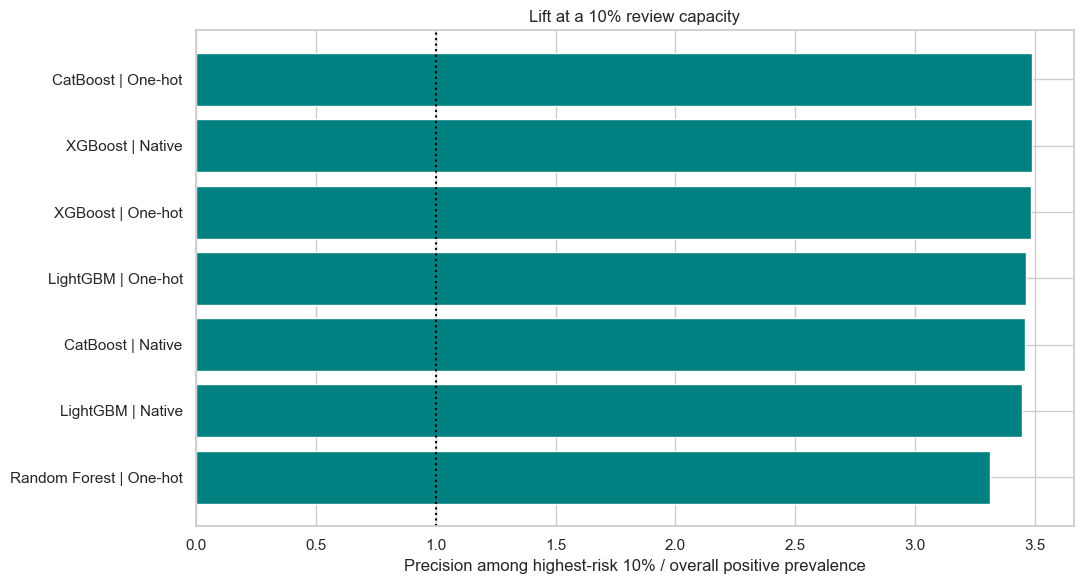

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, representation in zip(axes, ["One-hot", "Native"]):
    subset = results[(results["Representation"] == representation) & (results["Version"] == "Tuned")]
    for _, record in subset.iterrows():
        order = np.argsort(-test_predictions[record["Model_ID"]], kind="stable")
        x = np.arange(1, len(y_test) + 1) / len(y_test)
        gains = np.cumsum(y_test[order]) / y_test.sum()
        ax.plot(np.r_[0, x], np.r_[0, gains], label=record["Algorithm"], color=colors[record["Algorithm"]])
    ax.plot([0, 1], [0, 1], "k:", label="Random review")
    ax.axvline(0.1, color="gray", linestyle="--")
    ax.set(title=representation, xlabel="Fraction of applicants reviewed", ylabel="Fraction of positive cases captured")
    ax.legend()
fig.suptitle("Cumulative gains — tuned models")
save_figure("07_cumulative_gains")

plot_data = results[results["Version"] == "Tuned"].sort_values("Lift_At_Top_10_Percent")
plt.figure(figsize=(11, 6))
plt.barh(plot_data["Algorithm"] + " | " + plot_data["Representation"], plot_data["Lift_At_Top_10_Percent"], color="teal")
plt.axvline(1, color="black", linestyle=":")
plt.xlabel("Precision among highest-risk 10% / overall positive prevalence")
plt.title("Lift at a 10% review capacity")
save_figure("08_lift_top10")

## 15. Actual classification errors at frozen thresholds


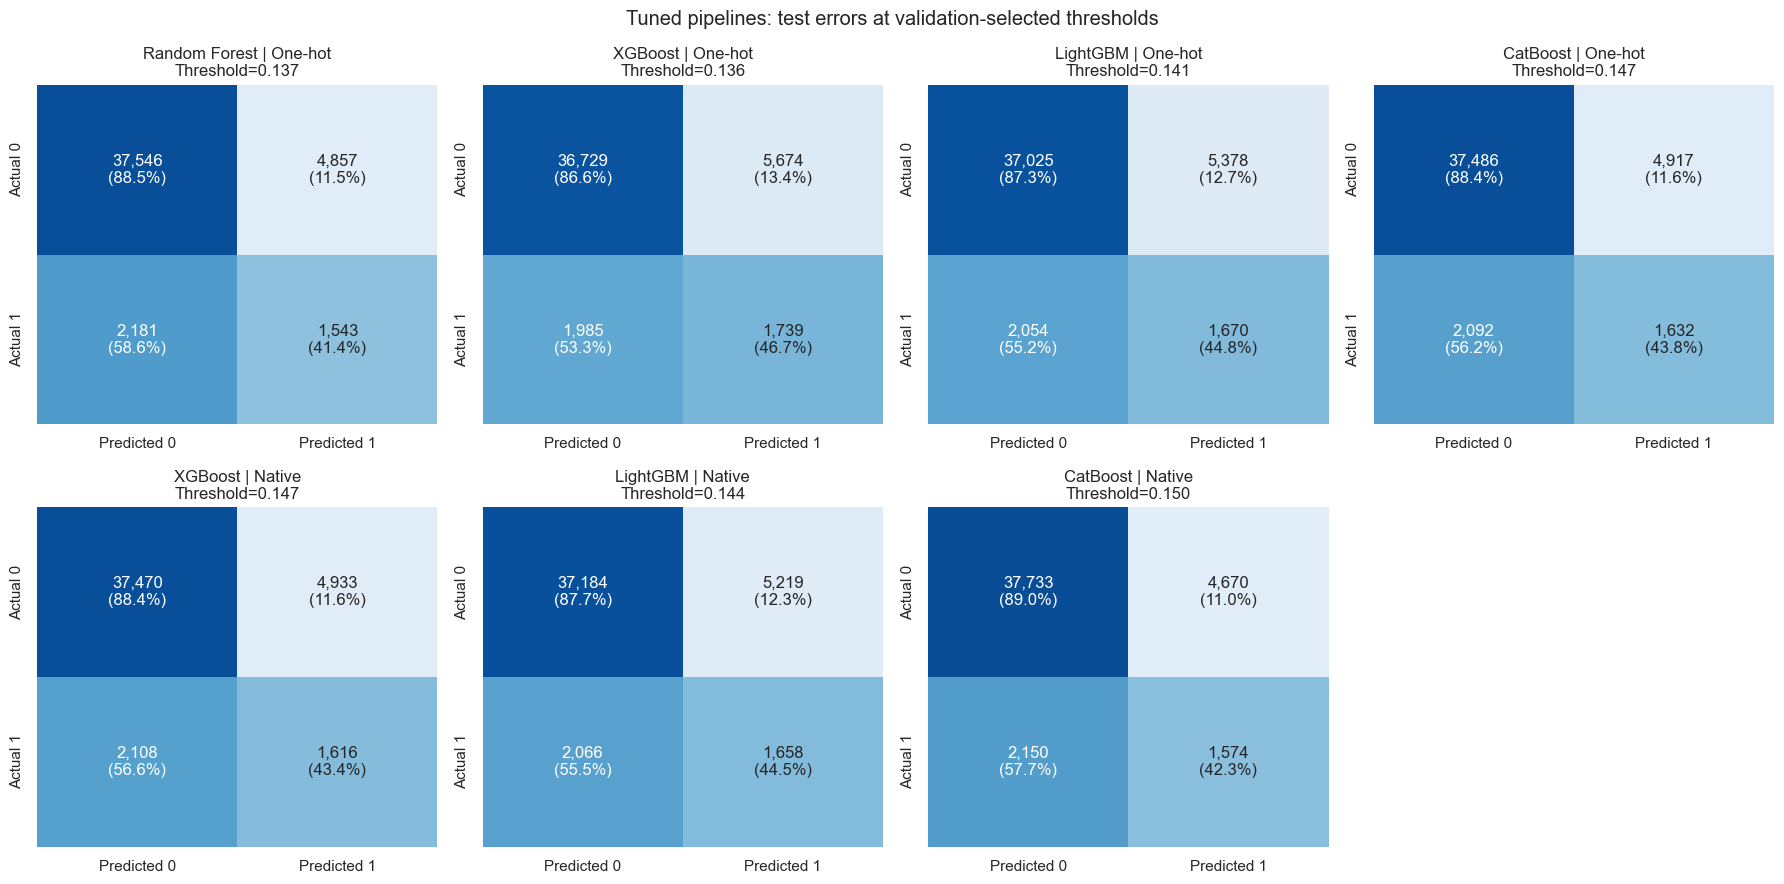

In [20]:
tuned = results[results["Version"] == "Tuned"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (_, record) in zip(axes.flat, tuned.iterrows()):
    matrix = np.array([[record["TN"], record["FP"]], [record["FN"], record["TP"]]], dtype=int)
    percentages = matrix / matrix.sum(axis=1, keepdims=True)
    annotations = np.array([[f"{matrix[i,j]:,}\n({percentages[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(percentages, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=["Predicted 0", "Predicted 1"], yticklabels=["Actual 0", "Actual 1"], ax=ax)
    ax.set_title(f"{record['Algorithm']} | {record['Representation']}\nThreshold={record['Threshold']:.3f}")
for ax in list(axes.flat)[len(tuned):]:
    ax.axis("off")
fig.suptitle("Tuned pipelines: test errors at validation-selected thresholds")
save_figure("09_confusion_matrices")

## 16. Threshold sensitivity — validation only


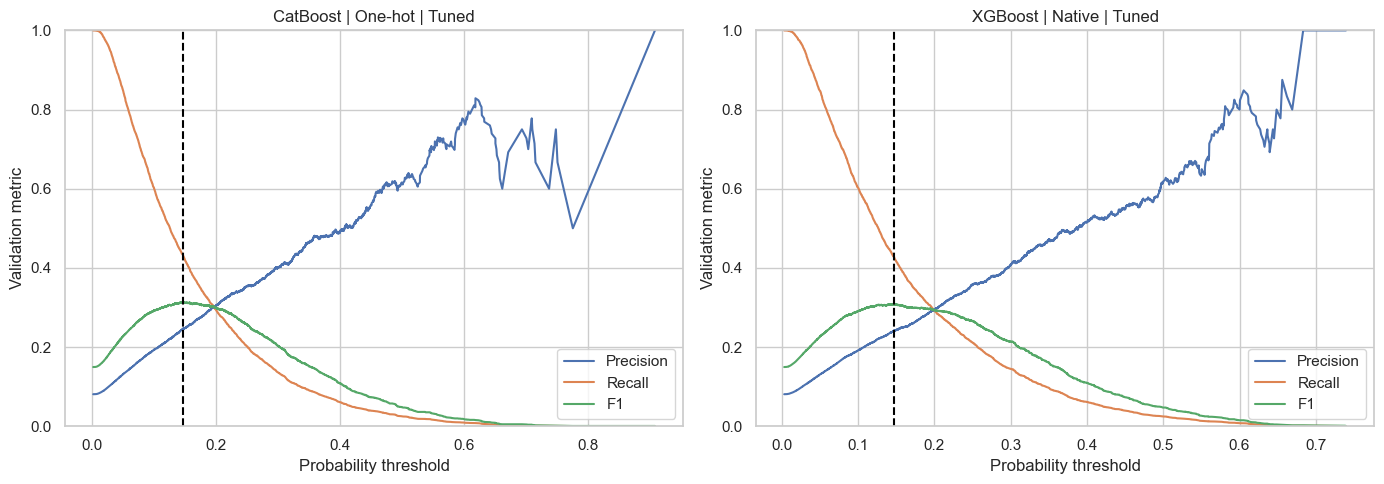

In [21]:
y_valid_reference = pd.read_csv(PROCESSED_DIR / "engineered" / "y_valid.csv")["TARGET"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (representation, model_id) in zip(axes, champions.items()):
    p, r, thresholds = precision_recall_curve(y_valid_reference, validation_predictions[model_id])
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-15)
    ax.plot(thresholds, p[:-1], label="Precision")
    ax.plot(thresholds, r[:-1], label="Recall")
    ax.plot(thresholds, f, label="F1")
    threshold = float(registry.loc[registry["Model_ID"] == model_id, "Threshold"].iloc[0])
    ax.axvline(threshold, color="black", linestyle="--")
    ax.set(title=label_lookup[model_id], xlabel="Probability threshold", ylabel="Validation metric", ylim=(0, 1))
    ax.legend()
save_figure("10_validation_threshold_sensitivity")

## 17. Computation trade-offs


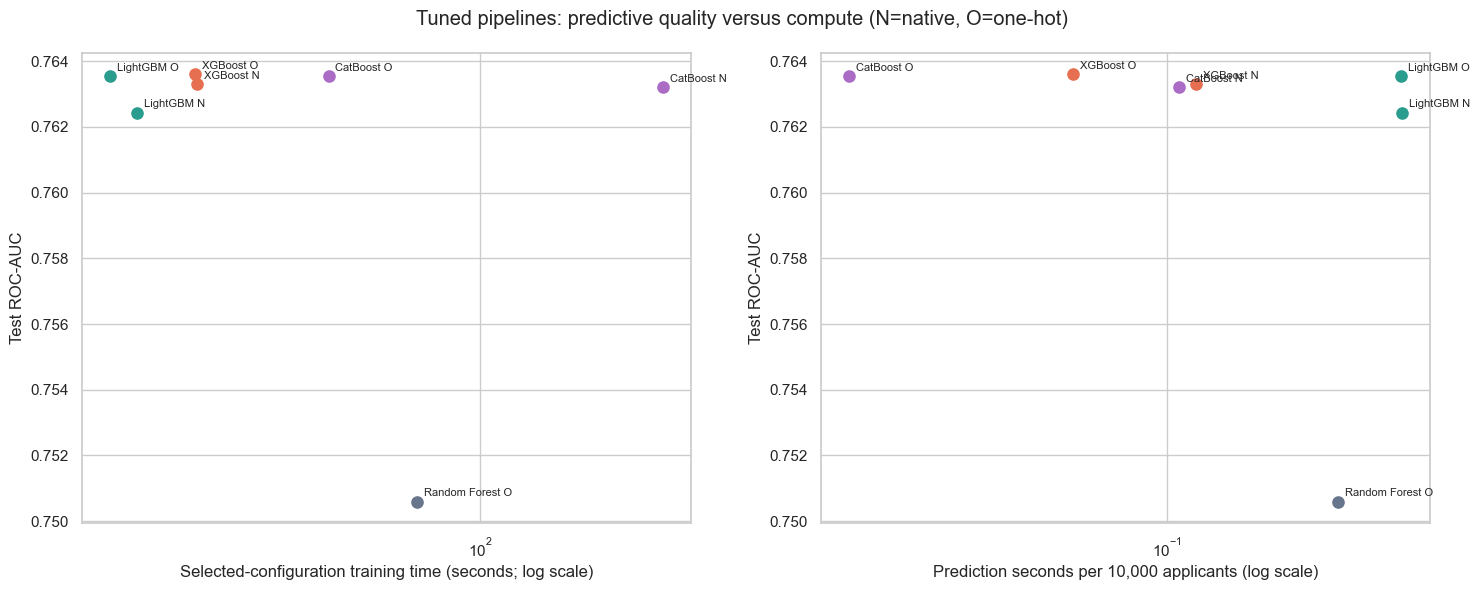

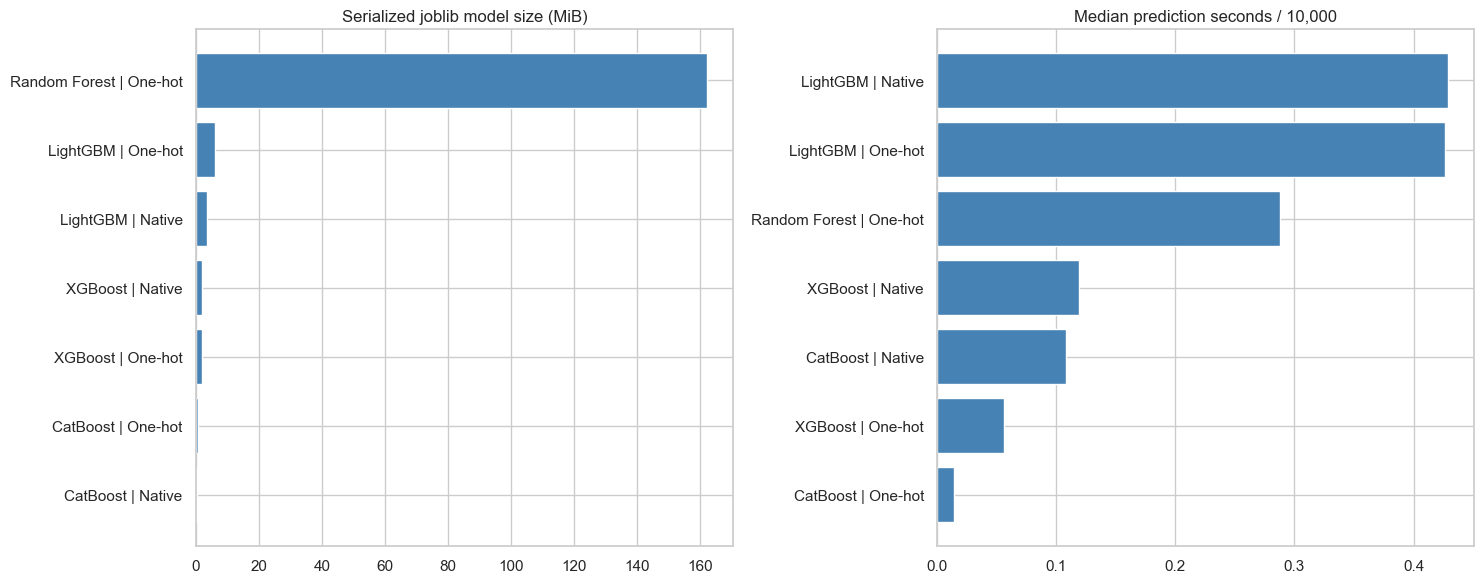

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, x_column, xlabel in [
    (axes[0], "Fit_Seconds", "Selected-configuration training time (seconds; log scale)"),
    (axes[1], "Prediction_Seconds_Per_10000", "Prediction seconds per 10,000 applicants (log scale)")
]:
    for _, record in tuned.iterrows():
        ax.scatter(record[x_column], record["ROC_AUC"], color=colors[record["Algorithm"]], s=65)
        ax.annotate(record["Algorithm"] + (" N" if record["Representation"] == "Native" else " O"),
                    (record[x_column], record["ROC_AUC"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_xscale("log")
    ax.set(xlabel=xlabel, ylabel="Test ROC-AUC")
fig.suptitle("Tuned pipelines: predictive quality versus compute (N=native, O=one-hot)")
save_figure("11_quality_vs_compute")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, column, title in [(axes[0], "Model_Size_MB", "Serialized joblib model size (MiB)"),
                          (axes[1], "Prediction_Seconds_Per_10000", "Median prediction seconds / 10,000")]:
    data = tuned.sort_values(column)
    ax.barh(data["Algorithm"] + " | " + data["Representation"], data[column], color="steelblue")
    ax.set_title(title)
save_figure("12_model_size_and_prediction_time")

## 18. Optuna progress — validation scores


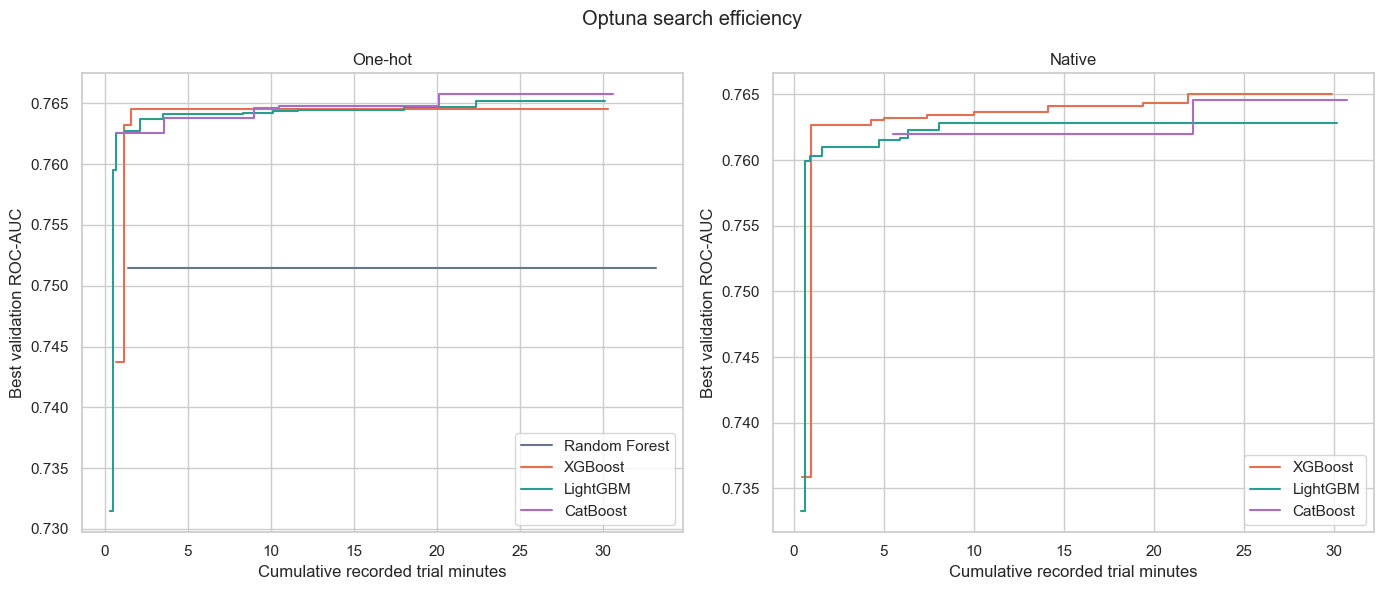

,Algorithm,Representation,Completed_Trials,Recorded_Trial_Seconds
0,Random Forest,One-hot,4,1991.433840
1,XGBoost,One-hot,58,1820.214435
2,LightGBM,One-hot,73,1807.087277
3,CatBoost,One-hot,38,1837.481711
4,XGBoost,Native,70,1792.469323
5,LightGBM,Native,68,1808.304007
6,CatBoost,Native,7,1841.975884


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
tuning_rows = []
for ax, representation in zip(axes, ["One-hot", "Native"]):
    folder = TRAINING_RESULTS if representation == "One-hot" else TRAINING_RESULTS / "native"
    for key in (["rf", "xgb", "lgb", "cat"] if representation == "One-hot" else ["xgb", "lgb", "cat"]):
        path = folder / f"{key}_optuna_trials.csv"
        if not path.exists():
            print("No saved trial CSV:", path)
            continue
        trials = pd.read_csv(path).sort_values("number")
        durations = (pd.to_datetime(trials["datetime_complete"]) - pd.to_datetime(trials["datetime_start"])).dt.total_seconds()
        trials["Cumulative_Minutes"] = durations.fillna(0).clip(lower=0).cumsum() / 60
        complete = trials.loc[trials["state"] == "COMPLETE"].copy()
        if complete.empty:
            continue
        ax.step(complete["Cumulative_Minutes"], complete["value"].cummax(), where="post",
                label=algorithm_names[key], color=colors[algorithm_names[key]])
        tuning_rows.append({"Algorithm": algorithm_names[key], "Representation": representation,
                            "Completed_Trials": len(complete), "Recorded_Trial_Seconds": durations.sum()})
    ax.set(title=representation, xlabel="Cumulative recorded trial minutes", ylabel="Best validation ROC-AUC")
    ax.legend()
fig.suptitle("Optuna search efficiency")
save_figure("13_optuna_progress")
pd.DataFrame(tuning_rows).to_csv(EVAL_DIR / "tuning_effort.csv", index=False)
display(pd.DataFrame(tuning_rows))

## 19. Paired score differences with uncertainty


,Comparison,Metric,Model_A,Model_B,Difference_B_Minus_A,Lower,Upper
0,Tuning: CatBoost | Native,ROC_AUC,cat_native_baseline,cat_native_tuned,0.0019,0.0008,0.0031
1,Tuning: CatBoost | Native,Average_Precision,cat_native_baseline,cat_native_tuned,0.0033,0.0001,0.0064
2,Tuning: CatBoost | One-hot,ROC_AUC,cat_onehot_baseline,cat_onehot_tuned,0.0029,0.0016,0.0042
3,Tuning: CatBoost | One-hot,Average_Precision,cat_onehot_baseline,cat_onehot_tuned,0.0051,0.0016,0.0087
4,Tuning: LightGBM | Native,ROC_AUC,lgb_native_baseline,lgb_native_tuned,0.0016,-0.0003,0.0032
5,Tuning: LightGBM | Native,Average_Precision,lgb_native_baseline,lgb_native_tuned,0.0006,-0.0033,0.0039
6,Tuning: LightGBM | One-hot,ROC_AUC,lgb_onehot_baseline,lgb_onehot_tuned,0.0017,0.0001,0.0037
7,Tuning: LightGBM | One-hot,Average_Precision,lgb_onehot_baseline,lgb_onehot_tuned,-0.0002,-0.0040,0.0039
8,Tuning: Random Forest | One-hot,ROC_AUC,rf_onehot_baseline,rf_onehot_tuned,0.0055,0.0030,0.0081
9,Tuning: Random Forest | One-hot,Average_Precision,rf_onehot_baseline,rf_onehot_tuned,0.0047,0.0011,0.0084


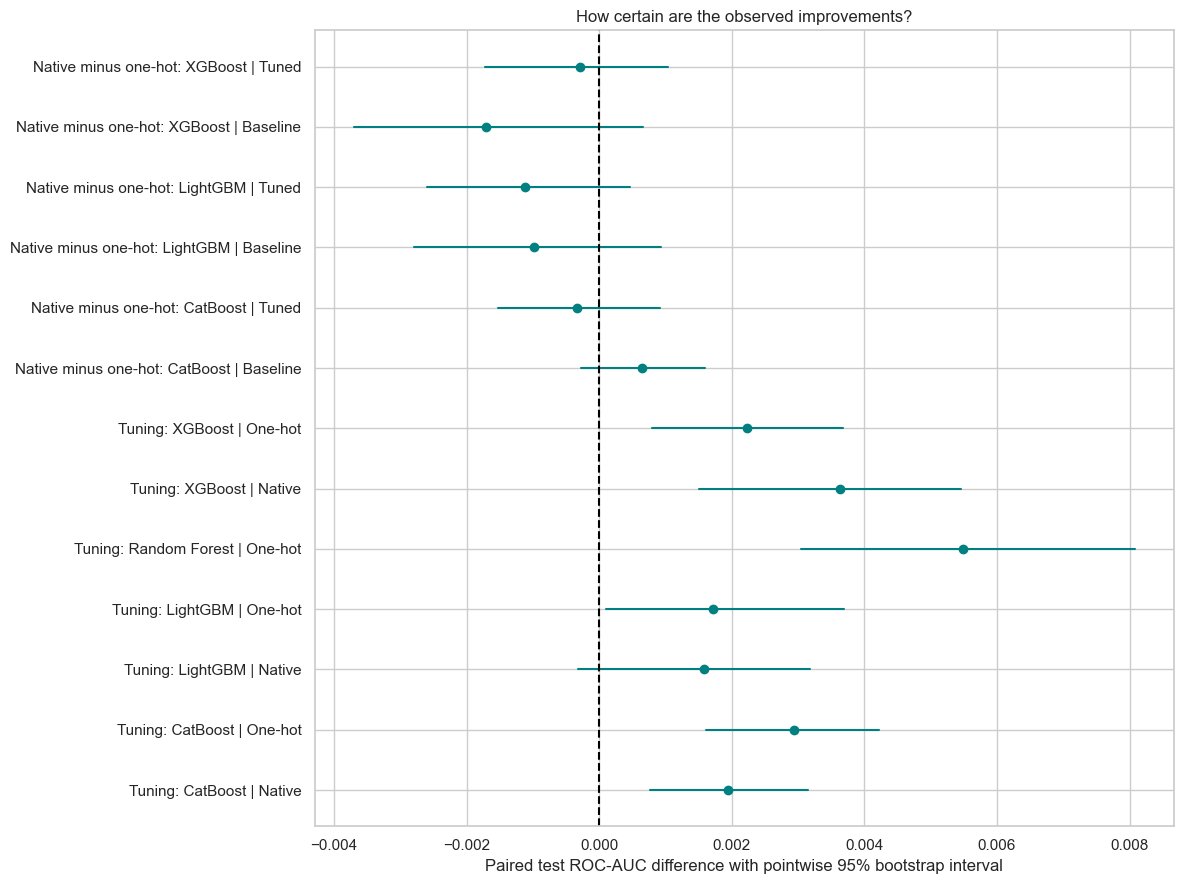

In [24]:
pair_specs = []
for (algorithm, representation), group in results.groupby(["Algorithm", "Representation"]):
    a = group.loc[group["Version"] == "Baseline", "Model_ID"].iloc[0]
    b = group.loc[group["Version"] == "Tuned", "Model_ID"].iloc[0]
    pair_specs.append((f"Tuning: {algorithm} | {representation}", a, b))
for (algorithm, stage), group in results[results["Algorithm"] != "Random Forest"].groupby(["Algorithm", "Version"]):
    a = group.loc[group["Representation"] == "One-hot", "Model_ID"].iloc[0]
    b = group.loc[group["Representation"] == "Native", "Model_ID"].iloc[0]
    pair_specs.append((f"Native minus one-hot: {algorithm} | {stage}", a, b))

paired_rows = []
for label, a, b in pair_specs:
    for metric, samples in [("ROC_AUC", bootstrap_auc), ("Average_Precision", bootstrap_ap)]:
        differences = np.array(samples[b]) - np.array(samples[a])
        scores = results.set_index("Model_ID")[metric]
        paired_rows.append({"Comparison": label, "Metric": metric, "Model_A": a, "Model_B": b,
                            "Difference_B_Minus_A": scores[b] - scores[a],
                            "Lower": np.percentile(differences, 2.5), "Upper": np.percentile(differences, 97.5)})
paired_results = pd.DataFrame(paired_rows)
paired_results.to_csv(EVAL_DIR / "paired_score_differences.csv", index=False)
display(paired_results.round(4))

plot_data = paired_results[paired_results["Metric"] == "ROC_AUC"].reset_index(drop=True)
plt.figure(figsize=(12, 9))
for position, row in plot_data.iterrows():
    plt.plot([row["Lower"], row["Upper"]], [position, position], color="teal")
    plt.scatter(row["Difference_B_Minus_A"], position, color="teal")
plt.axvline(0, color="black", linestyle="--")
plt.yticks(range(len(plot_data)), plot_data["Comparison"])
plt.xlabel("Paired test ROC-AUC difference with pointwise 95% bootstrap interval")
plt.title("How certain are the observed improvements?")
save_figure("14_paired_auc_differences")

## 20. Feature importance for tuned models


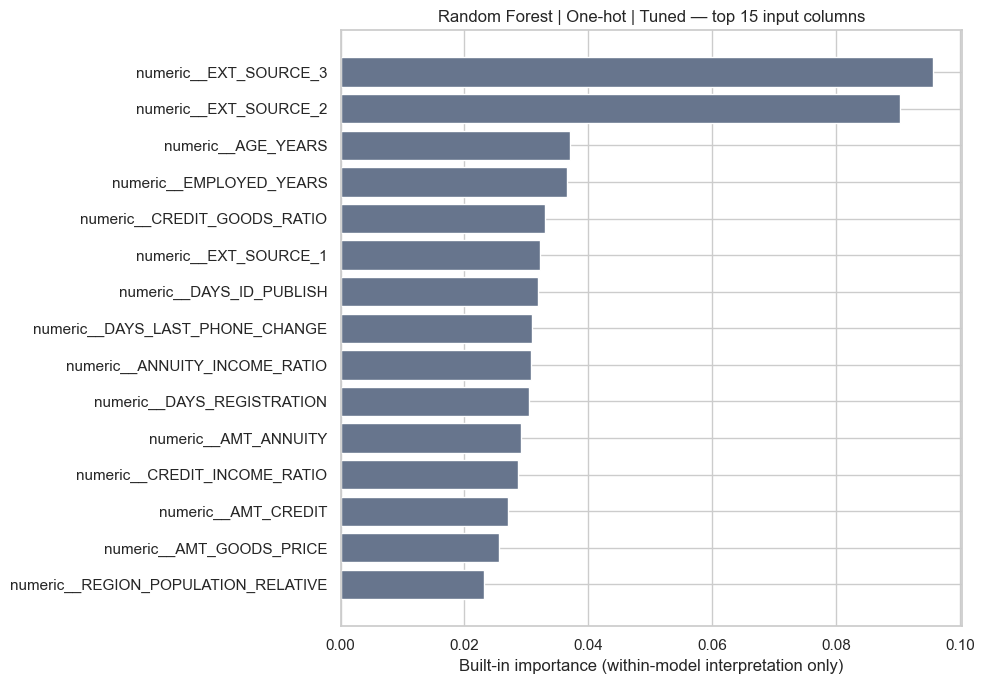

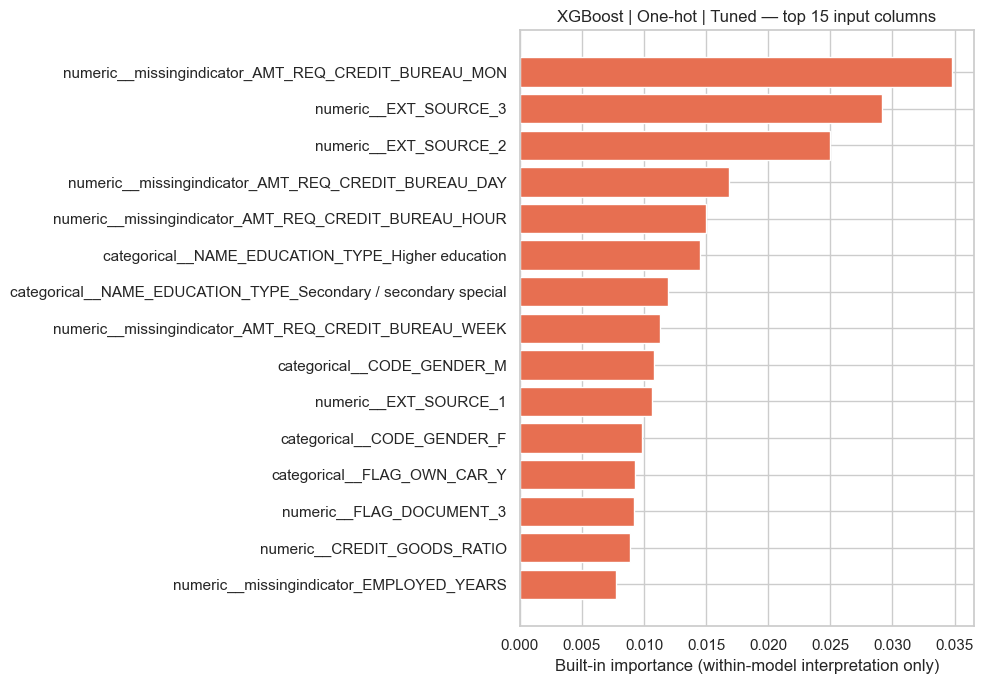

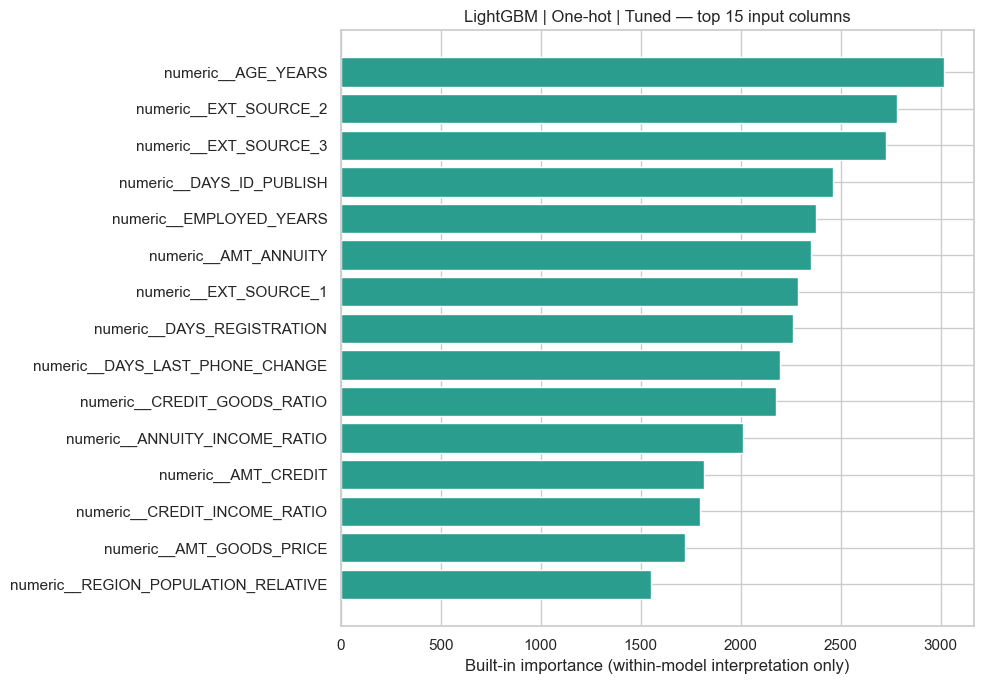

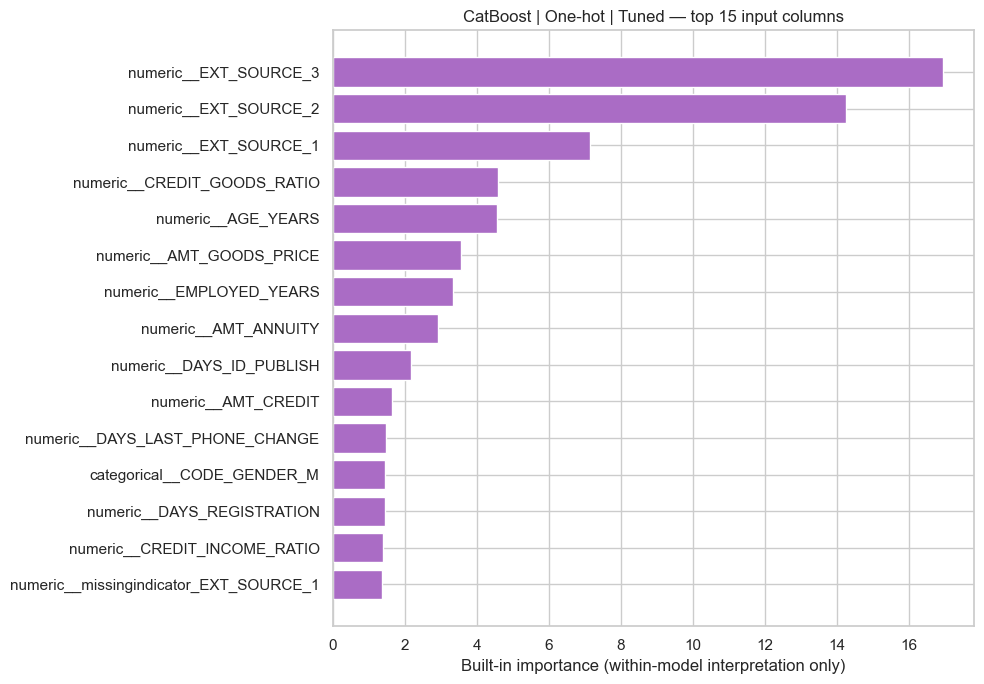

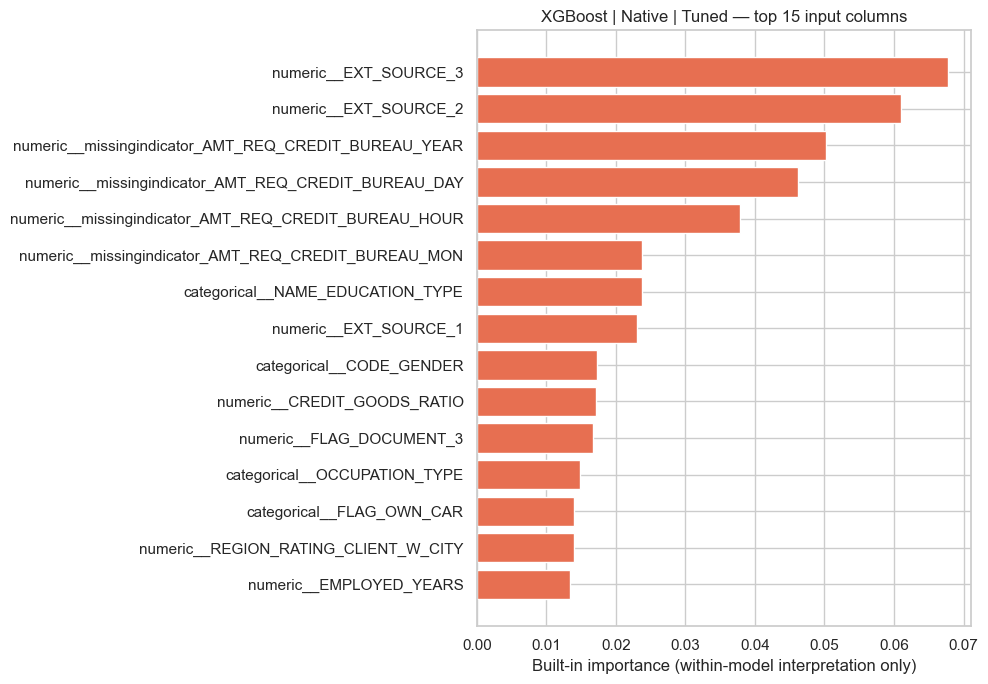

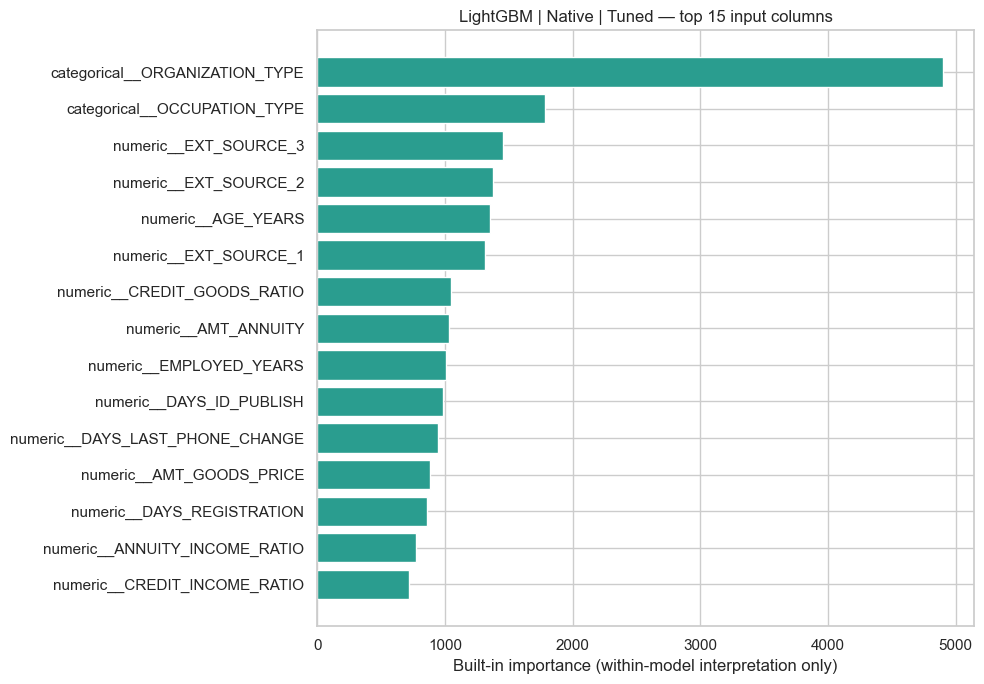

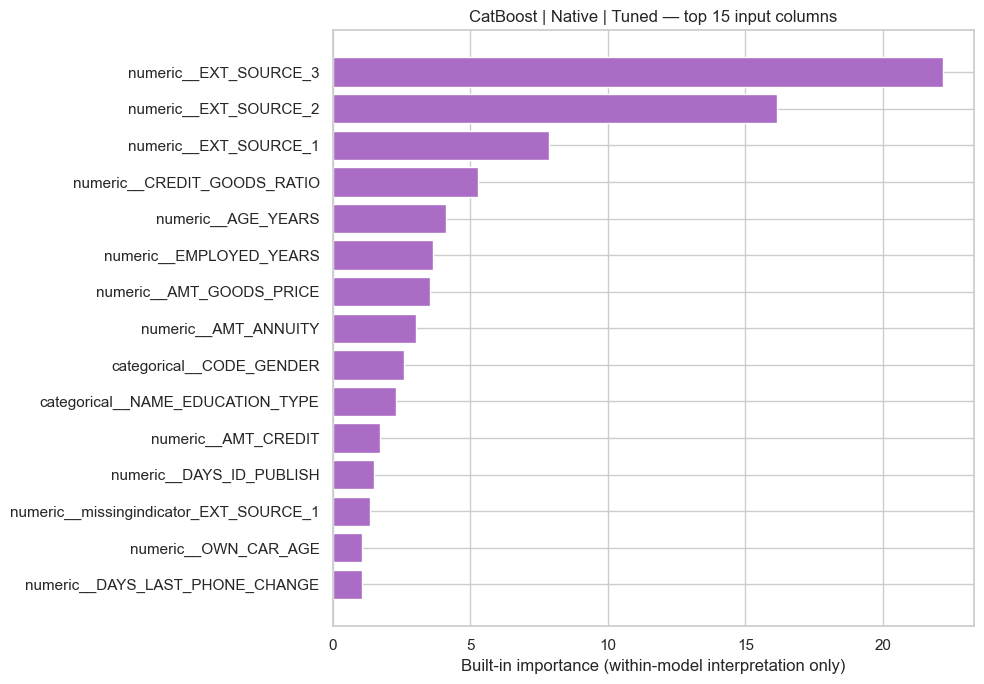

In [25]:
for _, record in tuned.iterrows():
    model = joblib.load(record["Model_Path"])
    if record["Representation"] == "Native":
        info = joblib.load(record["Input_Info_Path"])
        names = info["original_columns"]
    else:
        names = pd.read_csv(PROCESSED_DIR / record["Feature_Folder"] / "X_train.csv", nrows=0).columns.tolist()
    importance = np.asarray(model.feature_importances_)
    assert len(importance) == len(names)
    table = pd.DataFrame({"Feature": names, "Importance": importance}).sort_values("Importance", ascending=False)
    table.to_csv(EVAL_DIR / f"{record['Model_ID']}_feature_importance.csv", index=False)
    plot_data = table.head(15).sort_values("Importance")
    plt.figure(figsize=(10, 7))
    plt.barh(plot_data["Feature"], plot_data["Importance"], color=colors[record["Algorithm"]])
    plt.xlabel("Built-in importance (within-model interpretation only)")
    plt.title(label_lookup[record["Model_ID"]] + " — top 15 input columns")
    save_figure(f"15_importance_{record['Model_ID']}")
    del model
    gc.collect()

## 21. Feature screening belongs to validation


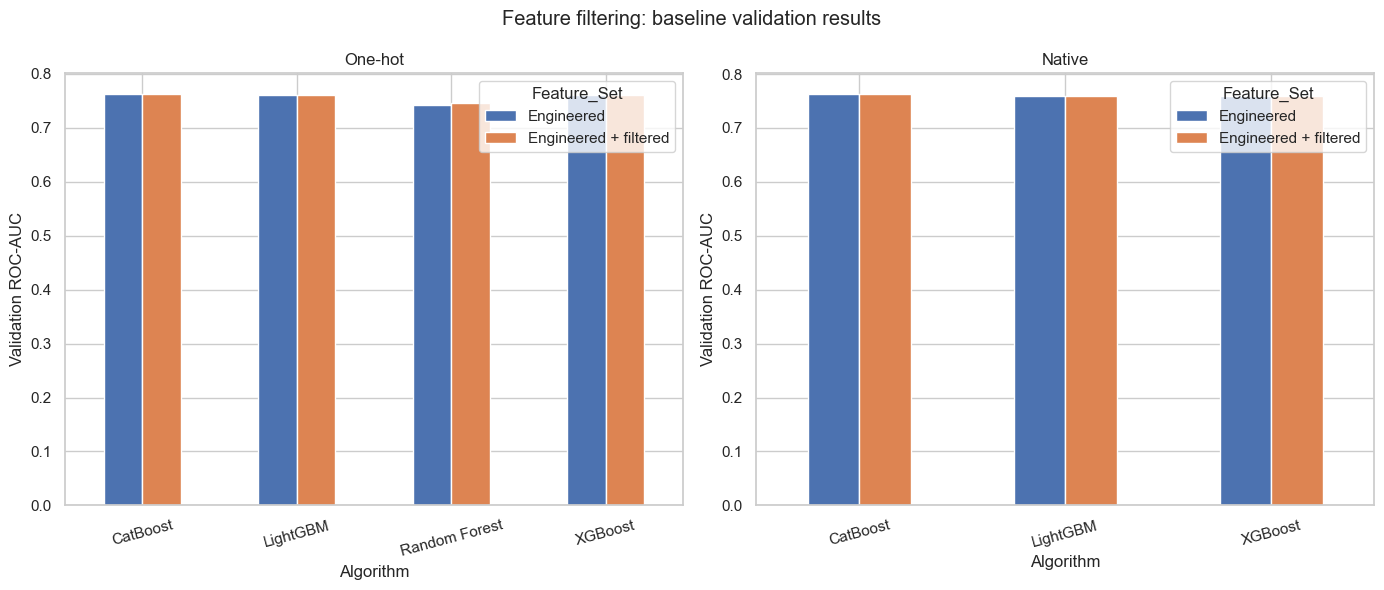

In [26]:
screening_rows = []
for representation in ["One-hot", "Native"]:
    folder = TRAINING_RESULTS if representation == "One-hot" else TRAINING_RESULTS / "native"
    for key in (["rf", "xgb", "lgb", "cat"] if representation == "One-hot" else ["xgb", "lgb", "cat"]):
        frame = pd.read_csv(folder / f"{key}_baseline_comparison.csv")
        frame["Representation"] = representation
        screening_rows.append(frame)
screening = pd.concat(screening_rows, ignore_index=True)
screening.to_csv(EVAL_DIR / "feature_screening_validation.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, representation in zip(axes, ["One-hot", "Native"]):
    data = screening[screening["Representation"] == representation]
    pivot = data.pivot(index="Model", columns="Feature_Set", values="ROC_AUC")
    pivot.plot.bar(ax=ax, rot=15)
    ax.set(title=representation, ylabel="Validation ROC-AUC", xlabel="Algorithm")
fig.suptitle("Feature filtering: baseline validation results")
save_figure("16_feature_screening_validation")

In [27]:
highest_observed = results.loc[results["ROC_AUC"].idxmax()]
print("HOME CREDIT — OBSERVED TEST RESULTS")
print(f"Test applicants: {len(y_test):,}; positive prevalence: {np.mean(y_test):.2%}")
print(f"Highest observed test AUC: {highest_observed['Label']} = {highest_observed['ROC_AUC']:.4f}")
print("This is descriptive; model choices were fixed using validation.")
for representation, model_id in champions.items():
    row = results.loc[results["Model_ID"] == model_id].iloc[0]
    print(f"\nValidation-selected {representation} representative: {row['Algorithm']}")
    print(f"Test AUC {row['ROC_AUC']:.4f}; AP {row['Average_Precision']:.4f}; log loss {row['Log_Loss']:.4f}")
    print(f"Top 10% review captures {row['Recall_At_Top_10_Percent']:.1%} of positive cases.")
    print(f"Frozen threshold {row['Threshold']:.3f}: {int(row['TP']):,} detected, {int(row['FN']):,} missed, {int(row['FP']):,} false alerts.")

results.to_csv(EVAL_DIR / "home_credit_final_master_table.csv", index=False)
print("\nTables, prediction files and figures saved to:", EVAL_DIR)

HOME CREDIT — OBSERVED TEST RESULTS
Test applicants: 46,127; positive prevalence: 8.07%
Highest observed test AUC: XGBoost | One-hot | Tuned = 0.7636
This is descriptive; model choices were fixed using validation.

Validation-selected One-hot representative: CatBoost
Test AUC 0.7635; AP 0.2554; log loss 0.2443
Top 10% review captures 34.9% of positive cases.
Frozen threshold 0.147: 1,632 detected, 2,092 missed, 4,917 false alerts.

Validation-selected Native representative: XGBoost
Test AUC 0.7633; AP 0.2535; log loss 0.2443
Top 10% review captures 34.9% of positive cases.
Frozen threshold 0.147: 1,616 detected, 2,108 missed, 4,933 false alerts.

Tables, prediction files and figures saved to: C:\Case Study Trees\HomeCreditStudy\results\home_credit_evaluation
